In [ ]:
import numpy as np
from scipy.stats import norm
from scipy.optimize import minimize
import time
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

def gaussian_F(x):
    return norm.cdf(x)

def gaussian_F_prime(x):
    return norm.pdf(x)

# Alias for user-provided function
qfunc = norm.cdf

def neg_log_likelihood(w, P_hat, E):
    # Enforce average 0
    w = w - np.mean(w)
    val = 0
    for i in range(P_hat.shape[0]):
        for j in range(P_hat.shape[1]):
          if j != i:
            diff = w[j] - w[i]
            # Avoid numerical issues
            F_val = gaussian_F(diff)
            # Log likelihood
            val -= (P_hat[i, j] * np.log(F_val) + (1 - P_hat[i, j]) * np.log(1 - F_val))
    return val

def compute_weights_qfunc(P, E, verbose=False):
    n = P.shape[0]
    learning_rate = 0.1/ (n**0.5)
    max_iterations = 200

    w = np.zeros(n)
    # Gradient Descent
    for iter in range(max_iterations):
        gradient = np.zeros_like(w)
        for i in range(n):
            term = 0
            for j in range(n):
                if i != j and E[i, j]:
                    q = qfunc(w[j] - w[i])
                    term += (P[i, j] - q) * np.exp(- (w[j] - w[i])**2 / 2)/(q*(1-q) )
            gradient[i] = term

        norm_grad = np.linalg.norm(gradient)
        if norm_grad < 1e-7:
            if verbose: print(f"MLE Converged at iteration {iter}")
            break
        w = w - learning_rate * gradient

    w -= np.mean(w)
    return w

def solve_spectral(P_hat, max_iter=200, tol=1e-7, w_mle=None):
    n = P_hat.shape[0]
    w_curr = np.zeros(n)
    history = []

    for t in range(max_iter):
        M = np.zeros((n, n))
        for i in range(n):
            for j in range(n):
                if i == j: continue
                diff = w_curr[j] - w_curr[i]
                num =  P_hat[i, j] * gaussian_F_prime(diff)
                denom = gaussian_F(diff) * np.exp(w_curr[i])
                if denom < 1e-15: denom = 1e-15
                M[i, j] = num / denom

        row_sums = np.sum(M, axis=1)
        d = np.max(row_sums) * 1.5
        S = M / d
        for i in range(n):
            S[i, i] = 1.0 - row_sums[i] / d

        eigenvalues, eigenvectors = np.linalg.eig(S.T)
        dominant_eigenvalue_index = np.argmax(np.abs(eigenvalues))
        pi = np.real_if_close(np.abs(eigenvectors[:, dominant_eigenvalue_index]))
        pi = pi / np.sum(pi)

        w_new = np.log(pi + 1e-8)
        w_new -= np.mean(w_new)

        if w_mle is not None:
            history.append(np.linalg.norm(w_new - w_mle))

        dist = np.linalg.norm(w_new - w_curr)
        w_curr = w_new
        if dist < tol:
            break

    return w_curr, history

def run_simulation():
    np.random.seed(42)
    n_values = np.arange(10, 61, 10)
    k_values = [5, 10, 15]
    num_trials = 0

    results_a = {k: {'mle': [], 'spec': [], 'mle_std': [], 'spec_std': []} for k in k_values}

    print("Running Simulation for Plot A...")
    for k in k_values:
        for n in n_values:
            print(f"Running n={n} for k={k}")
            errors_mle = []
            errors_spec = []
            for _ in range(num_trials):
                # Ground Truth
                w_star = np.random.uniform(-0.5, 0.5, n)
                w_star -= np.mean(w_star)

                E_matrix = np.ones((n, n)) - np.eye(n)
                P_hat = np.zeros((n, n))
                for i in range(n):
                    for j in range(i+1, n):
                        prob = gaussian_F(w_star[j] - w_star[i])
                        P_hat[i, j] = np.random.binomial(k, prob) / k
                        P_hat[j, i] = 1 - P_hat[i, j]

                w_mle = compute_weights_qfunc(P_hat, E_matrix)
                w_spec, _ = solve_spectral(P_hat)

                errors_mle.append(np.linalg.norm(w_mle - w_star))
                errors_spec.append(np.linalg.norm(w_spec - w_star))

            results_a[k]['mle'].append(np.mean(errors_mle))
            results_a[k]['spec'].append(np.mean(errors_spec))
            results_a[k]['mle_std'].append(np.std(errors_mle) / np.sqrt(num_trials))
            results_a[k]['spec_std'].append(np.std(errors_spec) / np.sqrt(num_trials))
        print(f"Completed k={k}")

    print("Running Simulation for Plot B...")
    n_fixed = 30
    num_trials_b = 5
    max_iter_b = 50
    history_results = {k: [] for k in k_values}

    for k in k_values:
        trial_histories = []
        for _ in range(num_trials_b):
            w_star = np.random.uniform(-0.5, 0.5, n_fixed)
            w_star -= np.mean(w_star)
            E_matrix = np.ones((n_fixed, n_fixed)) - np.eye(n_fixed)
            P_hat = np.zeros((n_fixed, n_fixed))
            for i in range(n_fixed):
                for j in range(i+1, n_fixed):
                    prob = gaussian_F(w_star[j] - w_star[i])
                    P_hat[i, j] = np.random.binomial(k, prob) / k
                    P_hat[j, i] = 1 - P_hat[i, j]

            w_mle = compute_weights_qfunc(P_hat, E_matrix)
            _, history = solve_spectral(P_hat, max_iter=max_iter_b, w_mle=w_mle)

            # Pad history if converged early
            if len(history) < max_iter_b:
                history.extend([history[-1]] * (max_iter_b - len(history)))
            trial_histories.append(history[:max_iter_b])

        history_results[k] = np.mean(trial_histories, axis=0)
        print(f"Completed k={k} for iterations")

    # Plotting
    with PdfPages('simulation_results.pdf') as pdf:
        # # Plot A
        # plt.figure(figsize=(8, 6))
        # for k in k_values:
        #     plt.errorbar(n_values, results_a[k]['mle'], yerr=results_a[k]['mle_std'], label=f'MLE (k={k})', capsize=5, fmt='-o')
        #     plt.errorbar(n_values, results_a[k]['spec'], yerr=results_a[k]['spec_std'], label=f'Spec (k={k})', capsize=5, fmt='--s')

        # plt.xlabel('n (Number of items)')
        # plt.ylabel('L2 Error (vs w*)')
        # plt.legend()
        # plt.grid(True, linestyle='--', alpha=0.7)
        # pdf.savefig()
        # plt.close()

        # Plot B
        plt.figure(figsize=(8, 6))
        for k in k_values:
            plt.plot(range(1, max_iter_b + 1), history_results[k], label=f'k={k}')

        plt.xlabel('Iteration number of spectral algo')
        plt.ylabel('L2 Error (vs estimated w_mle)')
        plt.yscale('log')
        plt.legend()
        plt.grid(True, which="both", linestyle='--', alpha=0.7)
        pdf.savefig()
        plt.close()

    print("Plots saved to simulation_results.pdf")

if __name__ == "__main__":
    run_simulation()



Running Simulation for Plot A...
Running n=10 for k=5
Running n=20 for k=5
Running n=30 for k=5
Running n=40 for k=5
Running n=50 for k=5
Running n=60 for k=5
Completed k=5
Running n=10 for k=10
Running n=20 for k=10
Running n=30 for k=10
Running n=40 for k=10
Running n=50 for k=10
Running n=60 for k=10
Completed k=10
Running n=10 for k=15
Running n=20 for k=15
Running n=30 for k=15
Running n=40 for k=15
Running n=50 for k=15
Running n=60 for k=15
Completed k=15
Running Simulation for Plot B...


/usr/local/lib/python3.12/dist-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:218: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:175: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:210: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Completed k=5 for iterations
Completed k=10 for iterations
Completed k=15 for iterations
Plots saved to simulation_results.pdf


In [ ]:
gaussian_F(-3)

np.float64(0.0013498980316300933)

In [ ]:
import numpy as np
from scipy.stats import norm
from scipy.optimize import minimize
import time
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

def gaussian_F(x):
    return norm.cdf(x)

def gaussian_F_prime(x):
    return norm.pdf(x)

# Alias for user-provided function
qfunc = norm.cdf

def neg_log_likelihood(w, P_hat, E):
    # Enforce average 0
    w = w - np.mean(w)
    val = 0
    for i in range(P_hat.shape[0]):
        for j in range(P_hat.shape[1]):
          if j != i:
            diff = w[j] - w[i]
            # Avoid numerical issues
            F_val = gaussian_F(diff)
            # Log likelihood
            val -= (P_hat[i, j] * np.log(F_val) + (1 - P_hat[i, j]) * np.log(1 - F_val))
    return val

def compute_weights_qfunc(P, E, verbose=False):
    n = P.shape[0]
    learning_rate = 0.1/ (n**0.5)
    max_iterations = 200

    w = np.zeros(n)
    # Gradient Descent
    for iter in range(max_iterations):
        gradient = np.zeros_like(w)
        for i in range(n):
            term = 0
            for j in range(n):
                if i != j and E[i, j]:
                    q = qfunc(w[j] - w[i])
                    term += (P[i, j] - q) * np.exp(- (w[j] - w[i])**2 / 2)/(q*(1-q) )
            gradient[i] = term

        norm_grad = np.linalg.norm(gradient)
        if norm_grad < 1e-7:
            if verbose: print(f"MLE Converged at iteration {iter}")
            break
        w = w - learning_rate * gradient

    w -= np.mean(w)
    return w

def solve_spectral(P_hat, max_iter=200, tol=1e-7, w_mle=None):
    n = P_hat.shape[0]
    w_curr = np.zeros(n)
    history = []

    for t in range(max_iter):
        M = np.zeros((n, n))
        for i in range(n):
            for j in range(n):
                if i == j: continue
                diff = w_curr[j] - w_curr[i]
                num =  P_hat[i, j] * gaussian_F_prime(diff)
                denom = gaussian_F(diff) * np.exp(w_curr[i])
                if denom < 1e-15: denom = 1e-15
                M[i, j] = num / denom

        row_sums = np.sum(M, axis=1)
        d = np.max(row_sums) * 1.5
        S = M / d
        for i in range(n):
            S[i, i] = 1.0 - row_sums[i] / d

        eigenvalues, eigenvectors = np.linalg.eig(S.T)
        dominant_eigenvalue_index = np.argmax(np.abs(eigenvalues))
        pi = np.real_if_close(np.abs(eigenvectors[:, dominant_eigenvalue_index]))
        pi = pi / np.sum(pi)

        w_new = np.log(pi + 1e-8)
        w_new -= np.mean(w_new)

        if w_mle is not None:
            history.append(np.linalg.norm(w_new - w_mle))

        dist = np.linalg.norm(w_new - w_curr)
        w_curr = w_new
        if dist < tol:
            break

    return w_curr, history

def run_simulation():
    np.random.seed(42)
    n_values_a = np.arange(10, 61, 10)
    k_values_a = [5, 10, 15]
    num_trials_a = 0  # Keep it zero as requested

    print("Skipping Simulation for Plot A (num_trials=0)...")

    print("Running Simulation for Plot B...")
    n_values_b = [15, 30]
    k_values_b = [5, 10]
    num_trials_b = 5
    max_iter_b = 50

    plt.figure(figsize=(10, 7))
    for n in n_values_b:
        print(f"Running convergence simulation for n={n}...")
        for k in k_values_b:
            trial_histories = []
            for trial in range(num_trials_b):
                # Ground Truth
                w_star = np.random.uniform(-0.5, 0.5, n)
                w_star -= np.mean(w_star)
                E_matrix = np.ones((n, n)) - np.eye(n)

                # Sample probabilities
                P_hat = np.zeros((n, n))
                for i in range(n):
                    for j in range(i+1, n):
                        prob = gaussian_F(w_star[j] - w_star[i])
                        P_hat[i, j] = np.random.binomial(k, prob) / k
                        P_hat[j, i] = 1 - P_hat[i, j]

                # Compute MLE and Spectral history
                w_mle = compute_weights_qfunc(P_hat, E_matrix)
                _, history = solve_spectral(P_hat, max_iter=max_iter_b, w_mle=w_mle)

                # Pad history if converged early
                if len(history) < max_iter_b:
                    history.extend([history[-1]] * (max_iter_b - len(history)))
                trial_histories.append(history[:max_iter_b])

            mean_history = np.mean(trial_histories, axis=0)
            plt.plot(range(1, max_iter_b + 1), mean_history, label=f'n={n}, k={k}', linewidth=2)
            print(f"  Completed k={k}")

    plt.xlabel('Iteration number', fontsize=18)
    plt.ylabel('L2 Error', fontsize=18)
    plt.yscale('log')
    plt.legend(fontsize=20)
    plt.grid(True, which="both", linestyle='--', alpha=0.7)

    pdf_filename = 'convergence_combined.pdf'
    with PdfPages(pdf_filename) as pdf:
        pdf.savefig()
    plt.close()
    print(f"Combined plot saved to {pdf_filename}")

if __name__ == "__main__":
    run_simulation()


Skipping Simulation for Plot A (num_trials=0)...
Running Simulation for Plot B...
Running convergence simulation for n=15...
  Completed k=5
  Completed k=10
Running convergence simulation for n=30...
  Completed k=5
  Completed k=10
Combined plot saved to convergence_combined.pdf


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import svd
import os

def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

def generate_theta_star(n, m, r, kappa, max_val=1.5):
    """
    Generates Theta* = U Sigma V^T
    Satisfies V^T 1 = 0 and incoherence.
    """
    # Random orthogonal U
    U, _ = np.linalg.qr(np.random.normal(size=(n, r)))

    # Random orthogonal V such that V^T 1 = 0
    V_raw = np.random.normal(size=(m, r))
    ones = np.ones((m, 1))
    V_proj = V_raw - ones @ (ones.T @ V_raw) / m
    V, _ = np.linalg.qr(V_proj)

    # Singular values
    sigma_max = 5.0 * np.sqrt(n * m)
    sigma_min = 1.0 * np.sqrt(n * m)
    # sigma_min should be sigma_max / kappa if we want exactly kappa?
    # Actually the user specified:
    # sigma_max = 5 sqrt(nm), sigma_min = 1.0 sqrt(nm)
    # and rest in between.
    s = np.linspace(sigma_min, sigma_max, r)
    Sigma = np.diag(s)

    Theta_star = U @ Sigma @ V.T

    # Center rows (though V^T 1 = 0 should already handle this)
    Theta_star -= np.mean(Theta_star, axis=1, keepdims=True)

    # Scale to ensure magnitude is less than max_val
    curr_max = np.max(np.abs(Theta_star))
    Theta_star = Theta_star * (max_val / curr_max)
    # print(Theta_star)
    return Theta_star

def sample_comparisons(Theta_star, K, p):
    n, m = Theta_star.shape
    A = np.zeros((n, m, m), dtype=int)
    Y = np.zeros((n, m, m))

    for i in range(n):
        for j in range(m):
            for k in range(j + 1, m):
                if np.random.rand() < p:
                    A[i, j, k] = 1
                    A[i, k, j] = 1
                    prob = sigmoid(Theta_star[i, j] - Theta_star[i, k])
                    counts = np.random.binomial(K, prob)
                    Y[i, j, k] = counts / K
                    Y[i, k, j] = 1.0 - Y[i, j, k]
    return A, Y

def phase_i_marginal_mle_gd(A_i, Y_i, max_iter=400, lr=0.005):
    m = A_i.shape[0]
    theta = np.zeros(m)

    for _ in range(max_iter):
        # Diff[j, k] = theta[j] - theta[k]
        Diff = theta[:, np.newaxis] - theta[np.newaxis, :]
        Psi = sigmoid(Diff)
        # Gradient = sum_k A_jk * (psi_jk - y_jk)
        Grad_M = A_i * (Psi - Y_i)
        grad = np.sum(Grad_M, axis=1)

        theta -= lr * grad
        theta -= np.mean(theta)
        if np.linalg.norm(grad) < 1e-6:
            break
    return theta

def phase_i_initialization(A, Y, r, Theta_star):
    n, m, _ = A.shape
    Theta_0 = np.zeros((n, m))
    for i in range(n):
        Theta_0[i] = phase_i_marginal_mle_gd(A[i], Y[i])
    # print("Error before phase 2:", np.linalg.norm(Theta_0 - Theta_star), "inf:", np.max(np.abs(Theta_0 - Theta_star)))
    U, S, Vt = svd(Theta_0, full_matrices=False)
    U_r = U[:, :r]
    S_r = S[:r]
    Vt_r = Vt[:r, :]

    X0 = U_r @ np.diag(np.sqrt(S_r))
    Y0 = Vt_r.T @ np.diag(np.sqrt(S_r))
    return X0, Y0, Theta_0

def phase_ii_refinement(X0, Y0, A, Y, rho, eta, T):
    X, Y_f = X0.copy(), Y0.copy()
    n, m, _ = A.shape

    for t in range(T):
        Theta = X @ Y_f.T
        Grad_Theta = np.zeros((n, m))

        for i in range(n):
            # Theta_delta[j, k] = Theta[i, j] - Theta[i, k]
            Theta_delta = Theta[i, :, np.newaxis] - Theta[i, np.newaxis, :]
            Psi_i = sigmoid(Theta_delta)
            # M_i[j, k] = A_ijk * (Psi_ijk - Y_ijk)
            M_i = A[i] * (Psi_i - Y[i])
            Grad_Theta[i, :] = np.sum(M_i, axis=1)

        gradX = (1.0 / m) * (Grad_Theta @ Y_f) + rho * X
        gradY = (1.0 / m) * (Grad_Theta.T @ X) + rho * Y_f

        X   -= eta * gradX
        Y_f -= eta * gradY
        # Y_f -= np.mean(Y_f, axis=0, keepdims=True)
        if np.sqrt(np.linalg.norm( gradX, ord='fro')**2 +  np.linalg.norm( gradY, ord='fro')**2 ) < 1e-5:
            break
    return X @ Y_f.T

def run_experiment_suite():
    ns = [20, 40, 60]
    ms = [60, 90, 120, 150, 180, 210, 240]
    r = 5
    kappa = 5
    K = 5
    p = 0.25
    eta = 0.002
    n_trials = 5

    results = {}

    for n in ns:
        for algo in ["Proposed", "Baseline", "GD random init"]:
            results[(n, algo)] = []

        for m in ms:
            rho = 0.01 * np.sqrt(np.log(m) / (p * K))

            print(f"Running n={n}, m={m}, rho={rho:.4f}, eta={eta:.6f}...")
            trial_errors = {"Proposed": {"fro": [], "inf": []},
                            "Baseline": {"fro": [], "inf": []},
                            "GD random init": {"fro": [], "inf": []}}

            for trial in range(n_trials):
                Theta_star = generate_theta_star(n, m, r, kappa)
                A, Y_data = sample_comparisons(Theta_star, K, p)
                T_phase2 = m * 5

                # Phase I Initialization
                X0, Y0, Theta_0 = phase_i_initialization(A, Y_data, r, Theta_star)

                # Category: Baseline (Error after Phase I only)
                def calc_errors(est, true):
                    err = est - true
                    fro = np.linalg.norm(err)
                    inf = np.max(np.abs(err))
                    return fro, inf

                f_base, i_base = calc_errors(Theta_0, Theta_star)
                trial_errors["Baseline"]["fro"].append(f_base)
                trial_errors["Baseline"]["inf"].append(i_base)

                # Category: Proposed (Error after Phase II refinement)
                Theta_est_prop = phase_ii_refinement(X0, Y0, A, Y_data, rho, eta, T_phase2)
                f_p, i_p = calc_errors(Theta_est_prop, Theta_star)
                trial_errors["Proposed"]["fro"].append(f_p)
                trial_errors["Proposed"]["inf"].append(i_p)

                # Category: Proposed2 (Phase II refinement from random initialization)
                X0_rnd = np.random.normal(0, 0.1, (n, r))
                Y0_rnd = np.random.normal(0, 0.1, (m, r))
                Y0_rnd -= np.mean(Y0_rnd, axis=0, keepdims=True)
                # Scale X0_rnd @ Y0_rnd.T to have value between between -1.5 and 1.5
                scale_fac = 1.5 / np.max(np.abs(X0_rnd @ Y0_rnd.T ))
                X0_rnd *= np.sqrt(scale_fac)
                Y0_rnd *= np.sqrt(scale_fac)

                Theta_est_rnd = phase_ii_refinement(X0_rnd, Y0_rnd, A, Y_data, rho, eta, T_phase2)

                f_p2, i_p2 = calc_errors(Theta_est_rnd, Theta_star)
                trial_errors["GD random init"]["fro"].append(f_p2)
                trial_errors["GD random init"]["inf"].append(i_p2)

            for algo in ["Proposed", "Baseline", "GD random init"]:
                avg_fro = np.mean(trial_errors[algo]["fro"])
                std_fro = np.std(trial_errors[algo]["fro"])
                avg_inf = np.mean(trial_errors[algo]["inf"])
                std_inf = np.std(trial_errors[algo]["inf"])
                results[(n, algo)].append((m, avg_fro, std_fro, avg_inf, std_inf))

    return ns, ms, results

if __name__ == "__main__":
    ns, ms, results = run_experiment_suite()
    # plot_all(ns, ms, results)



Running n=20, m=60, rho=0.0181, eta=0.002000...
Running n=20, m=90, rho=0.0190, eta=0.002000...
Running n=20, m=120, rho=0.0196, eta=0.002000...
Running n=20, m=150, rho=0.0200, eta=0.002000...
Running n=20, m=180, rho=0.0204, eta=0.002000...
Running n=20, m=210, rho=0.0207, eta=0.002000...
Running n=20, m=240, rho=0.0209, eta=0.002000...
Running n=40, m=60, rho=0.0181, eta=0.002000...
Running n=40, m=90, rho=0.0190, eta=0.002000...
Running n=40, m=120, rho=0.0196, eta=0.002000...
Running n=40, m=150, rho=0.0200, eta=0.002000...
Running n=40, m=180, rho=0.0204, eta=0.002000...
Running n=40, m=210, rho=0.0207, eta=0.002000...
Running n=40, m=240, rho=0.0209, eta=0.002000...
Running n=60, m=60, rho=0.0181, eta=0.002000...
Running n=60, m=90, rho=0.0190, eta=0.002000...
Running n=60, m=120, rho=0.0196, eta=0.002000...
Running n=60, m=150, rho=0.0200, eta=0.002000...
Running n=60, m=180, rho=0.0204, eta=0.002000...
Running n=60, m=210, rho=0.0207, eta=0.002000...
Running n=60, m=240, rho=0

<>:10: SyntaxWarning: invalid escape sequence '\|'
<>:12: SyntaxWarning: invalid escape sequence '\|'
<>:10: SyntaxWarning: invalid escape sequence '\|'
<>:12: SyntaxWarning: invalid escape sequence '\|'
/tmp/ipykernel_3371/752641677.py:10: SyntaxWarning: invalid escape sequence '\|'
  ("fro", False, "frobenius_error.pdf", "$\| \hat{\Theta} - \Theta^* \|_F$"),
/tmp/ipykernel_3371/752641677.py:12: SyntaxWarning: invalid escape sequence '\|'
  ("fro", True, "frobenius_error_log.pdf", "$\| \hat{\Theta} - \Theta^* \|_F$"),


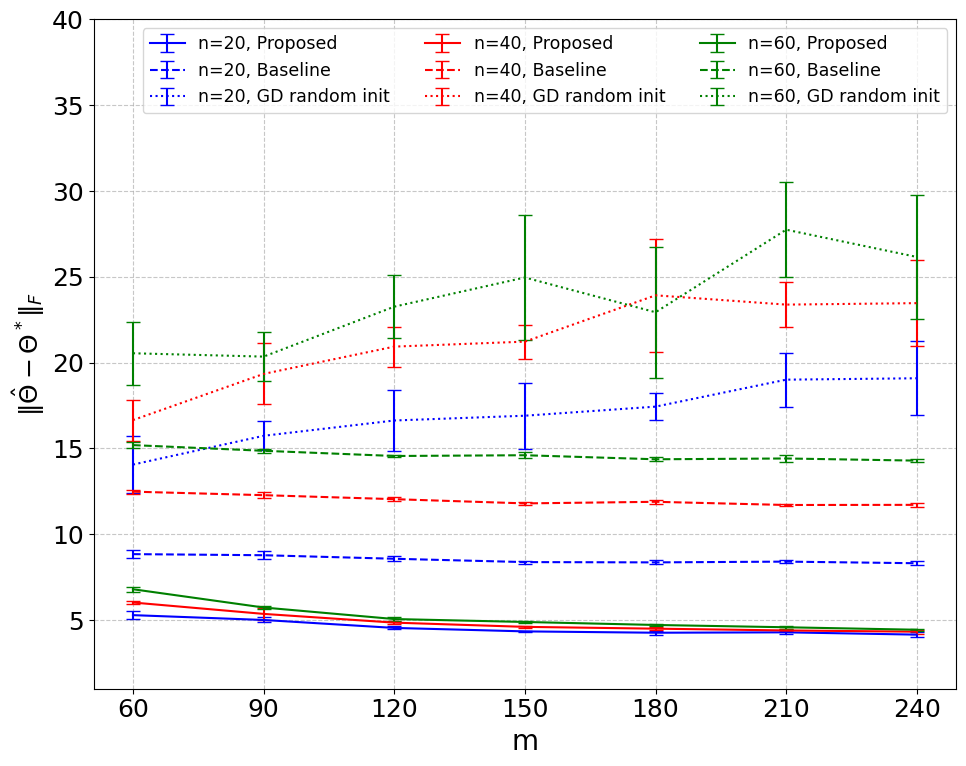

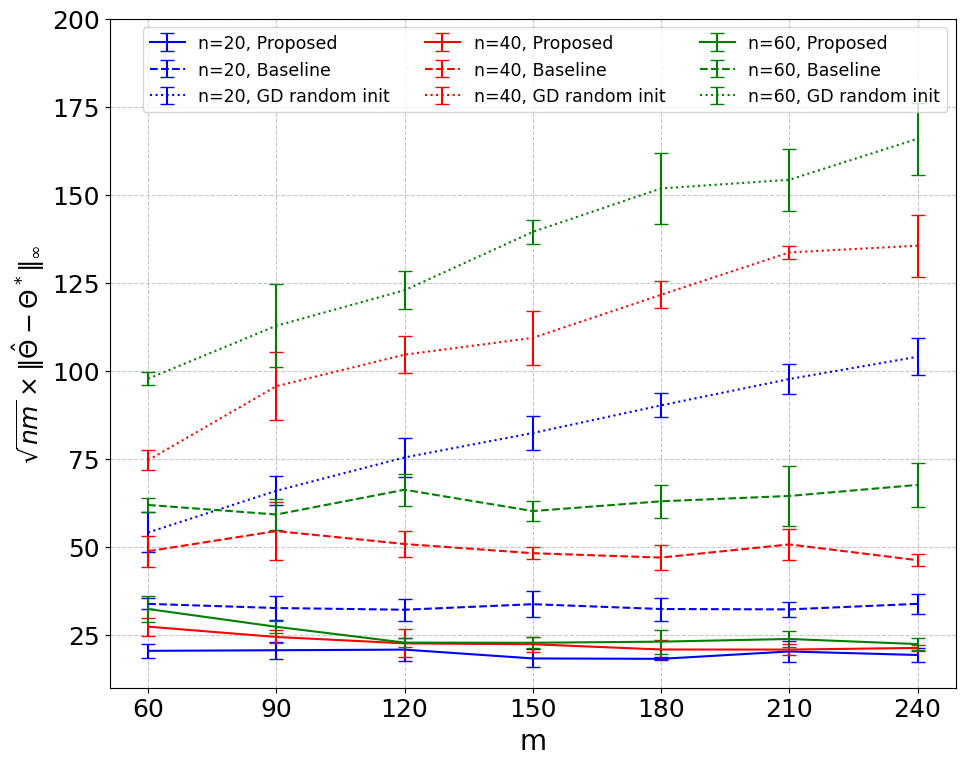

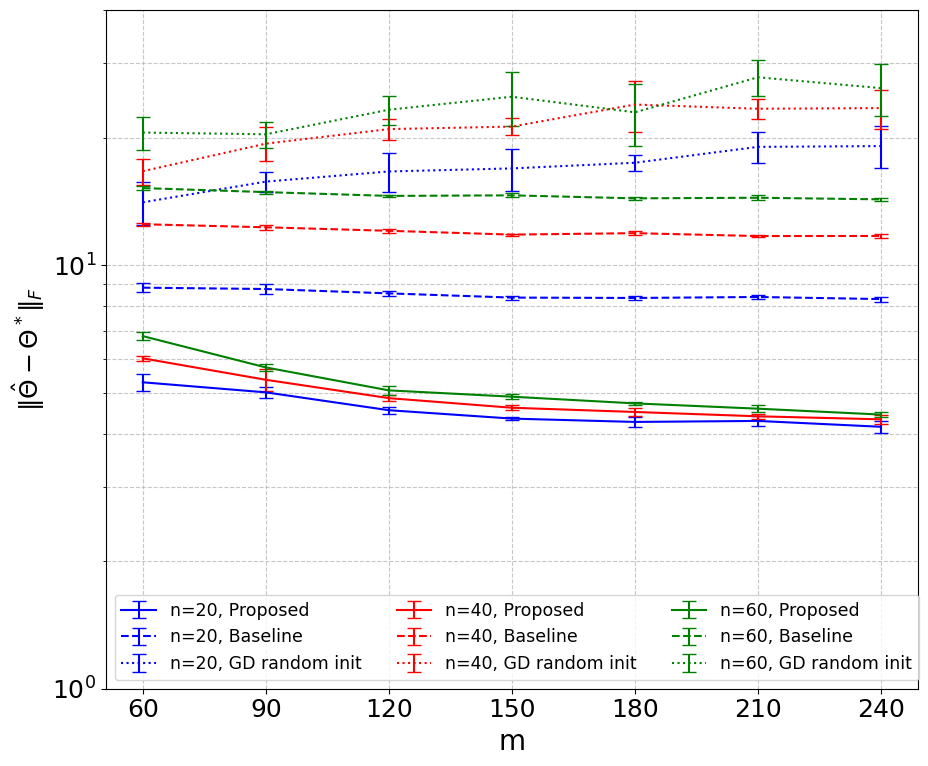

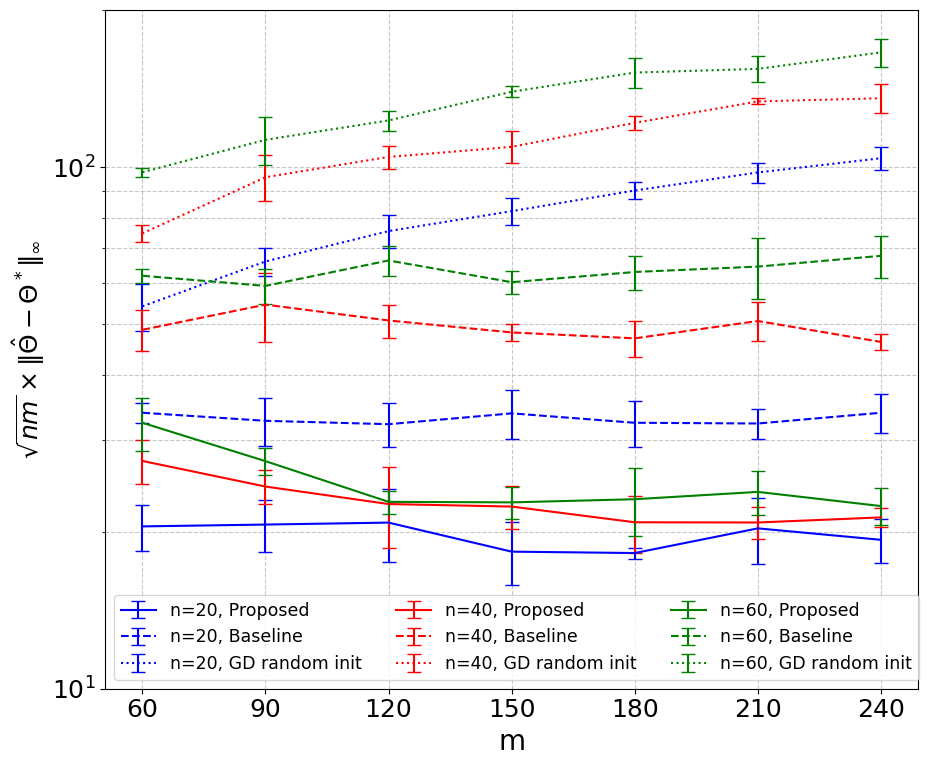

Plots saved: frobenius_error.pdf, infty_error.pdf, frobenius_error_log.pdf, infty_error_log.pdf


In [ ]:

def plot_all(ns, ms, results):
    plt.rcParams.update({'font.size': 18})

    categories = ["Proposed", "Baseline", "GD random init"]
    colors = {20: 'blue', 40: 'red', 60: 'green'}
    styles = {"Proposed": '-', "Baseline": '--', "GD random init": ':'}

    # Four figures: Linear Fro, Linear Inf, Log Fro, Log Inf
    configs = [
        ("fro", False, "frobenius_error.pdf", "$\| \hat{\Theta} - \Theta^* \|_F$"),
        ("inf", False, "infty_error.pdf", r"$\sqrt{nm} \times \| \hat{\Theta} - \Theta^* \|_\infty$"),
        ("fro", True, "frobenius_error_log.pdf", "$\| \hat{\Theta} - \Theta^* \|_F$"),
        ("inf", True, "infty_error_log.pdf", r"$\sqrt{nm} \times \| \hat{\Theta} - \Theta^* \|_\infty$")
    ]

    for err_type, is_log, filename, ylabel in configs:
        fig, ax = plt.subplots(figsize=(10, 8))
        for n in ns:
            for algo in categories:
                data = np.array(results[(n, algo)])
                m_vals = data[:, 0]
                if err_type == "fro":
                    avg = data[:, 1]
                    std = data[:, 2]
                else:
                    avg = data[:, 3] * np.sqrt(n * m_vals)
                    std = data[:, 4] * np.sqrt(n * m_vals)

                label = f"n={n}, {algo}"
                color = colors[n]
                style = styles[algo]

                ax.errorbar(m_vals, avg, yerr=std, label=label, color=color, linestyle=style, capsize=5)

        if is_log:
            ax.set_yscale('log')
        # turn on the grid
        ax.grid(True, which="both", linestyle='--', alpha=0.7)
        # set y range from 1 to 30 for frobenius and 1 to 200 for linfty
        if err_type == "fro":
            ax.set_ylim(1, 40)
        elif err_type == "inf":
            ax.set_ylim(10, 200)
        # set xticks [60, 90, 120, 150, 180, 210, 240]
        ax.set_xticks(ms)
        ax.set_xlabel("m", fontsize=20)
        ax.set_ylabel(ylabel, fontsize=18)
        # two column legend
        # if err_type == "fro":
        #     ax.legend(fontsize=20)
        # else:
        ax.legend(ncol =3, fontsize=12.5)
        ax.tick_params(axis='both', which='major', labelsize=18)
        fig.tight_layout()
        fig.savefig(filename)
        plt.show()
        plt.close(fig)


    print("Plots saved: frobenius_error.pdf, infty_error.pdf, frobenius_error_log.pdf, infty_error_log.pdf")

if __name__ == "__main__":
    plot_all(ns, ms, results)

Loading data from sushi3-2016/sushi3a.5000.10.order...
Loaded 5000 users and 10 items.
Generating train/test split...
Running experiments for n=50...
  Baseline Accuracy: 0.9000
  Proposed Accuracy: 0.8800
  GD Random Init Accuracy: 0.8778
Running experiments for n=100...
  Baseline Accuracy: 0.9022
  Proposed Accuracy: 0.8789
  GD Random Init Accuracy: 0.8878
Running experiments for n=200...
  Baseline Accuracy: 0.8956
  Proposed Accuracy: 0.8928
  GD Random Init Accuracy: 0.8867
Running experiments for n=500...
  Baseline Accuracy: 0.8989
  Proposed Accuracy: 0.8936
  GD Random Init Accuracy: 0.8956
Running experiments for n=1000...
  Baseline Accuracy: 0.8951
  Proposed Accuracy: 0.8921
  GD Random Init Accuracy: 0.8868
Running experiments for n=2000...
  Baseline Accuracy: 0.8919
  Proposed Accuracy: 0.8849
  GD Random Init Accuracy: 0.8856
Running experiments for n=5000...
  Baseline Accuracy: 0.8909
  Proposed Accuracy: 0.8862


/tmp/ipython-input-3150434821.py:7: RuntimeWarning: overflow encountered in exp
  return 1.0 / (1.0 + np.exp(-x))


  GD Random Init Accuracy: 0.3360
Saving plot...
Done! Plot saved as sushi_prediction_accuracy.pdf


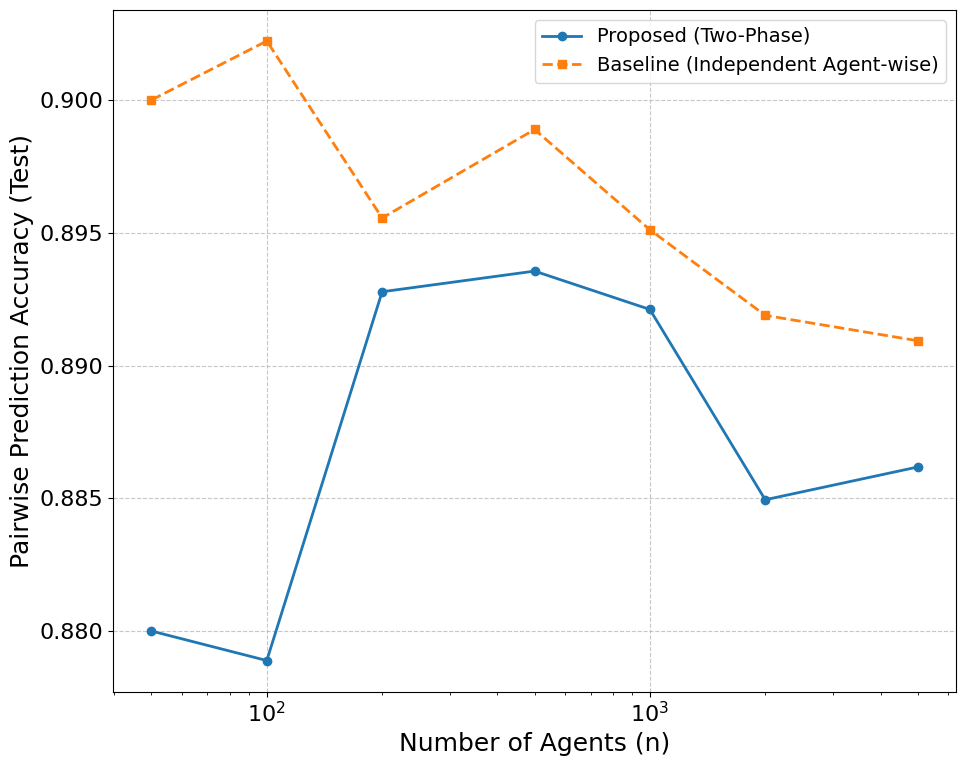

In [ ]:
# Set seeds for reproducibility
import os
np.random.seed(42)

def load_sushi_data(file_path):
    if not os.path.exists(file_path):
        raise FileNotFoundError(f"{file_path} not found. Please ensure the sushi data is extracted.")
    with open(file_path, 'r') as f:
        header = f.readline().strip()
        parts = header.split()
        m = int(parts[0]) # M is the first value (|X*|)
        rankings = []
        for line in f:
            parts = line.split()
            if not parts: continue
            # Format: 0 <length> <item1> <item2> ...
            # The original code used parts[2:] which seems to skip the first two columns of the user ranking lines.
            # Assuming the format "USER_ID K ITEM1 ITEM2 ... ITEMK", then ITEM1 starts at index 2.
            order = [int(x) for x in parts[2:]]
            rankings.append(order)
    return np.array(rankings), m

def generate_pairwise_data(rankings, train_frac=0.8):
    n, m = rankings.shape
    A_train = np.zeros((n, m, m))
    Y_train = np.zeros((n, m, m))
    test_pairs = [] # List of (user_idx, item_j, item_k, win_j)

    for i in range(n):
        order = rankings[i]
        # rank_map[item_id] = rank (lower is better)
        rank_map = {item: rank for rank, item in enumerate(order)}

        user_all_pairs = []
        for j in range(m):
            for k in range(j + 1, m):
                # Determine winner
                if rank_map[j] < rank_map[k]:
                    user_all_pairs.append((j, k, 1)) # j wins
                else:
                    user_all_pairs.append((j, k, 0)) # k wins

        np.random.shuffle(user_all_pairs)
        num_train = int(len(user_all_pairs) * train_frac)

        train_data = user_all_pairs[:num_train]
        test_data = user_all_pairs[num_train:]

        for j, k, win_j in train_data:
            A_train[i, j, k] = 1
            A_train[i, k, j] = 1
            Y_train[i, j, k] = win_j
            Y_train[i, k, j] = 1 - win_j

        for j, k, win_j in test_data:
            test_pairs.append((i, j, k, win_j))

    return A_train, Y_train, test_pairs

def evaluate_accuracy(Theta_est, test_pairs):
    correct = 0
    count = 0
    for i, j, k, win_j in test_pairs:
        if i >= Theta_est.shape[0]: continue

        pred_win_j = 1 if Theta_est[i, j] > Theta_est[i, k] else 0
        if pred_win_j == win_j:
            correct += 1
        count += 1
    return correct / count if count > 0 else 0


data_path = 'sushi3-2016/sushi3a.5000.10.order'
print(f"Loading data from {data_path}...")
rankings, m = load_sushi_data(data_path)
n_total = rankings.shape[0]
print(f"Loaded {n_total} users and {m} items.")

print("Generating train/test split...")
A_train, Y_train, test_pairs = generate_pairwise_data(rankings)

ns_eval = [50, 100, 200, 500, 1000, 2000, 5000]
r = 8
rho = 0.001 # Regularization parameter
eta = 0.05
T = 200

results = {"Proposed": [], "Baseline": [], "GD random init": []}

for n_sub in ns_eval:
    print(f"Running experiments for n={n_sub}...")
    A_sub = A_train[:n_sub]
    Y_sub = Y_train[:n_sub]
    test_sub = [p for p in test_pairs if p[0] < n_sub]

    # 1. Baseline: Marginal MLE (Phase I only)
    # Note: experiments.py requires A, Y, r, Theta_star. We pass None for Theta_star.
    X0, Y0, Theta_0 = phase_i_initialization(A_sub, Y_sub, r, None)
    acc_base = evaluate_accuracy(Theta_0, test_sub)
    results["Baseline"].append(acc_base)
    print(f"  Baseline Accuracy: {acc_base:.4f}")

    # 2. Proposed: Phase II refinement
    Theta_prop = phase_ii_refinement(X0, Y0, A_sub, Y_sub, rho, eta, T)
    acc_prop = evaluate_accuracy(Theta_prop, test_sub)
    results["Proposed"].append(acc_prop)
    print(f"  Proposed Accuracy: {acc_prop:.4f}")

    # 3. GD Random Init
    X_rnd = np.random.normal(0, 0.1, (n_sub, r))
    Y_rnd = np.random.normal(0, 0.1, (m, r))
    Theta_rnd = phase_ii_refinement(X_rnd, Y_rnd, A_sub, Y_sub, rho, eta, T)
    acc_rnd = evaluate_accuracy(Theta_rnd, test_sub)
    results["GD random init"].append(acc_rnd)
    print(f"  GD Random Init Accuracy: {acc_rnd:.4f}")

print("Saving plot...")
plt.figure(figsize=(10, 8))
plt.plot(ns_eval, results["Proposed"], 'o-', label="Proposed (Two-Phase)", linewidth=2)
plt.plot(ns_eval, results["Baseline"], 's--', label="Baseline (Independent Agent-wise)", linewidth=2)
# plt.plot(ns_eval, results["GD random init"], 'x:', label="GD Random Init", linewidth=2)

plt.xlabel("Number of Agents (n)", fontsize=18)
plt.ylabel("Pairwise Prediction Accuracy (Test)", fontsize=18)
# plt.title("Sushi Dataset: Exploiting Low-Rank Structure Improves Prediction", fontsize=16)
plt.legend(fontsize=14)
plt.grid(True, linestyle="--", alpha=0.7)
plt.xscale('log')
plt.tick_params(axis='both', which='major', labelsize=16)
plt.tight_layout()
plt.savefig("sushi_prediction_accuracy.pdf")
print("Done! Plot saved as sushi_prediction_accuracy.pdf")


In [ ]:
print("Saving plot...")
plt.figure(figsize=(10, 8))
plt.plot(ns_eval, results["Proposed"], 'o-', label="Proposed (Two-Phase)", linewidth=2)
plt.plot(ns_eval, results["Baseline"], 's--', label="Baseline (Independent Agent-wise)", linewidth=2)
# plt.plot(ns_eval, results["GD random init"], 'x:', label="GD Random Init", linewidth=2)

plt.xlabel("Number of Agents (n)", fontsize=18)
plt.ylabel("Pairwise Prediction Accuracy (Test)", fontsize=18)
# plt.title("Sushi Dataset: Exploiting Low-Rank Structure Improves Prediction", fontsize=16)
plt.legend(fontsize=14)
plt.grid(True, linestyle="--", alpha=0.7)
# plt.xscale('log')
plt.tick_params(axis='both', which='major', labelsize=16)
plt.tight_layout()
plt.savefig("sushi_prediction_accuracy.pdf")
print("Done! Plot saved as sushi_prediction_accuracy.pdf")

Saving plot...


NameError: name 'ns_eval' is not defined

<Figure size 1000x800 with 0 Axes>